# `cluster-barcodes.ipynb`

Clustering FASTQ barcodes using the Levenshtein distance and DBSCAN clustering.

In [176]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns # for heatmaps
import Levenshtein # for distance computation
from sklearn.cluster import DBSCAN # for clustering
from tqdm import trange # for loop progress bar
import BarcodeRemap as br
import pandas as pd

## Cluster using unique sequences in the file, not including counts.

In [139]:
# Get all unique sequences from the allreadcounts file
seq_df = br.BarcodeRemap().get_all_sequences('fish17_s6_rep1.allReadCounts')
unique_seqs = seq_df['sequence'].apply(lambda seq: seq.upper()).values
#unique_seqs = seq_df['sequence'].values
seq_counts = seq_df['count'].values
n_seqs = len(unique_seqs)

# Check if there are any duplicates in the 
for seq in unique_seqs:
    if len(np.where(unique_seqs == seq)) > 1:
        print('Warning: Duplicate barcodes')

print(f'There are {np.sum(seq_counts)} sequences in the file. {n_seqs} of them are unique.')

There are 31808 sequences in the file. 568 of them are unique.


In [123]:
# Test: Add the sequences from extendedfrags as well
def readFastq(filename):
    '''
    Read FASTQ file. Outputs two numpy arrays, `sequences` and `qualities`. `sequences` is an array of the nucleotide sequences
    
    Copied from this source: https://hossainlab.github.io/PY4B/notebooks/05-Working%20with%20FASTQ%20Sequence%20Data.html.
    The only change I made was to output numpy arrays at the end, instead of lists.
    '''
    sequences = []
    qualities = []
    with open(filename) as fh:
        while True:
            fh.readline() # skip name line
            seq = fh.readline().rstrip() # read base sequence
            fh.readline() # skip placeholder line
            qual = fh.readline().rstrip() #base quality line
            if len(seq) == 0:
                break
            sequences.append(seq)
            qualities.append(qual)
    return np.array(sequences), np.array(qualities)
sequences, qualities = readFastq('./fish17_s6_rep1_out.extendedFrags.fastq')

unique_seqs_ef, seq_counts_ef = np.unique(sequences, return_counts = True)
n_seqs = len(unique_seqs_ef)

unique_seqs = np.append(unique_seqs, unique_seqs_ef)
seq_counts = np.append(seq_counts, seq_counts_ef)
n_seqs = len(unique_seqs)
print(f'There are {np.sum(seq_counts)} sequences in the file. {n_seqs} of them are unique.')

There are 45470 sequences in the file. 1431 of them are unique.


In [140]:
# Compute Levenshtein distance between every pair of reads.
distances = np.zeros((n_seqs, n_seqs))
for i in range(n_seqs):
    for j in range(n_seqs):
        distances[i, j] = Levenshtein.distance(unique_seqs[i], unique_seqs[j])

In [141]:
# The `distances` matrix contains the distance between every pair of reads.
distances[:5,:5]

array([[ 0., 46., 38., 71., 74.],
       [46.,  0., 30., 83., 89.],
       [38., 30.,  0., 91., 90.],
       [71., 83., 91.,  0.,  6.],
       [74., 89., 90.,  6.,  0.]])

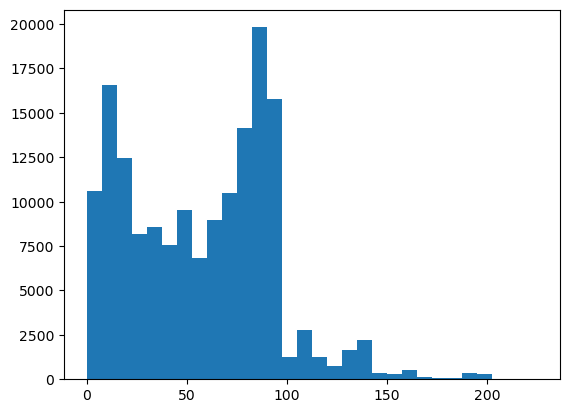

In [142]:
# Plot all the distances on a histogram. We see a bimodal distribution.
# Hopefully we can collapse all of the reads with very small distances.
plt.hist(distances[np.triu_indices(n_seqs)], bins=30);

<Axes: >

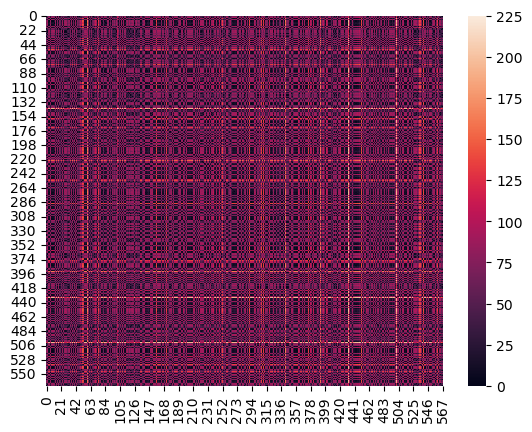

In [143]:
# The matrix plotted as a heatmap
sns.heatmap(distances)

In [162]:
# Set DBSCAN parameters
eps = 1.0  # tweak this based on your distance scale
min_samples = 2

db = DBSCAN(eps=eps, min_samples=min_samples, metric='precomputed')

# `labels` is an array containing the cluster identity of each read.
labels = db.fit_predict(distances)

In [163]:
# Print size of each cluster
unique_labels, cluster_counts = np.unique(labels, return_counts=True)

for label, count in zip(unique_labels, cluster_counts):
    print(f"Cluster {label}: {count} items")

# The interpretation here is that 67 reads are in cluster -1 (meaning they are in a cluster by themselves),
# cluster 0 groups 262 reads together, etc.

Cluster -1: 413 items
Cluster 0: 17 items
Cluster 1: 10 items
Cluster 2: 9 items
Cluster 3: 12 items
Cluster 4: 21 items
Cluster 5: 5 items
Cluster 6: 3 items
Cluster 7: 2 items
Cluster 8: 7 items
Cluster 9: 2 items
Cluster 10: 4 items
Cluster 11: 3 items
Cluster 12: 5 items
Cluster 13: 4 items
Cluster 14: 2 items
Cluster 15: 3 items
Cluster 16: 3 items
Cluster 17: 4 items
Cluster 18: 3 items
Cluster 19: 2 items
Cluster 20: 2 items
Cluster 21: 5 items
Cluster 22: 2 items
Cluster 23: 2 items
Cluster 24: 3 items
Cluster 25: 2 items
Cluster 26: 2 items
Cluster 27: 3 items
Cluster 28: 3 items
Cluster 29: 2 items
Cluster 30: 2 items
Cluster 31: 2 items
Cluster 32: 2 items
Cluster 33: 2 items


In [179]:
# Find the barcodes for the unclustered reads
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
unclustered_seqs = unique_seqs[np.where(labels == -1)]
unclustered_df = seq_df[seq_df['sequence'].apply(lambda seq: seq.upper()).isin(unclustered_seqs)]
unclustered_df.head(10)

,event,array,count,proportion,sequence
22,5D+34_NONE_NONE_NONE_3D+145_81D+170_81D+170_81...,22,59,0.001855,AGATCTCGAGCTCaagcttcgGACAGCAGTATCATATGGagtcGAG...
24,4D+38_15D+65_NONE_NONE_NONE_NONE_NONE_NONE_NON...,24,52,0.001635,AGATCTCGAGCTCaagcttcgGACAGCAGTATCATCGAGGagtcGA...
25,4I+38+GAGT_NONE_NONE_NONE_NONE_81D+170_81D+170...,25,47,0.001478,AGATCTCGAGCTCaagcttcgGACAGCAGTATCATCGAGAGTCTAT...
27,4D+38_NONE_NONE_NONE_NONE_81D+170_81D+170_81D+...,27,40,0.001258,AGATCTCGAGCTCaagcttcgGACAGCAGTATCATCGAGGagtcGA...
29,4D+38_54D+65_54D+65_54D+65_NONE_NONE_NONE_NONE...,29,37,0.001163,AGATCTCGAGCTCaagcttcgGACAGCAGTATCATCGAGGagtcGA...
31,4D+38_15D+65_NONE_54D+119_54D+119_54D+119_NONE...,31,36,0.001132,AGATCTCGAGCTCaagcttcgGACAGCAGTATCATCGAGGagtcGA...
34,2I+36+GA_NONE_NONE_NONE_NONE_NONE_NONE_NONE_13...,34,33,0.001037,AGATCTCGAGCTCaagcttcgGACAGCAGTATCATCGAGACTATGG...
35,4I+38+GAGT_NONE_NONE_54D+119_54D+119_54D+119_N...,35,33,0.001037,AGATCTCGAGCTCaagcttcgGACAGCAGTATCATCGAGAGTCTAT...
38,2I+36+GA_15D+65_NONE_54D+119_54D+119_54D+119_N...,38,25,0.000786,AGATCTCGAGCTCaagcttcgGACAGCAGTATCATCGAGACTATGG...
39,4I+38+GAGT_NONE_NONE_15D+111_72D+130_72D+130_7...,39,22,0.000692,AGATCTCGAGCTCaagcttcgGACAGCAGTATCATCGAGAGTCTAT...


<Axes: >

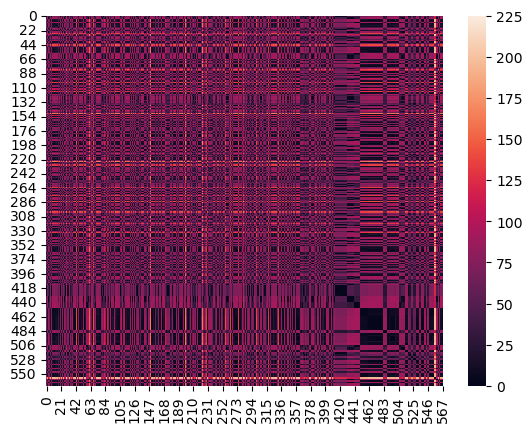

In [153]:
# Re-order the distance matrix based on the clusters and then plot.
sorted_indices = np.argsort(labels)
reordered_distances = distances[np.ix_(sorted_indices, sorted_indices)]

sns.heatmap(reordered_distances)
# The giant black square in the middle represents one cluster.

<Axes: >

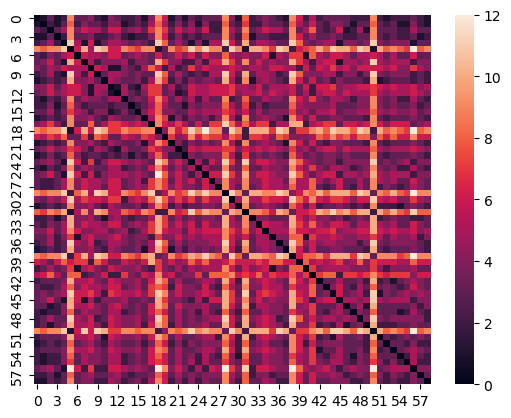

In [159]:
# Plot distances within the biggest cluster.
i = 4
indices_cluster_i = np.where(labels == i)[0]

cluster_i_seqs = unique_seqs[indices_cluster_i]
cluster_i_distances = distances[np.ix_(indices_cluster_i, indices_cluster_i)]

sns.heatmap(cluster_i_distances)

# Note that all of the sequences in this cluster have distance 4 or less from one another.

In [148]:
# Interestingly, the 120th sequence has distance 1 from almost every other sequence in this cluster,
# which may suggest that it is the "central" (or correct) sequence.
# This is clear in the heatmap above by the horizontal and vertical lines.
cluster_i_distances[120,:]

IndexError: index 120 is out of bounds for axis 0 with size 17

In [149]:
# I did the clustering in a way that ignored the number of occurances of each sequence,
# but here are the counts of each sequence in our big cluster.
counts_cluster_i = seq_counts[indices_cluster_i]
counts_cluster_i

# We see that one sequence has the most reads, suggesting that it is the correct
# sequence (and every other read has small errors).

array([11979,   107,    45,    16,    13,     6,     4,     2,     2,
           2,     2,     1,     1,     1,     1,     1,     1])

In [150]:
# Compute the index corresponding to this large count.
argmax_indices = np.where(counts_cluster_i == np.max(counts_cluster_i))[0]
if len(argmax_indices) > 1:
    raise Exception('There are multiple sequences that achieve the max read count. Deal with this somehow')
else:
    index_high_count = argmax_indices[0]

print(f'Within the cluster, the index of the sequence that has the most reads is {index_high_count}. It contains {counts_cluster_i[index_high_count]} reads.')

# Hey look! We've seen 120 before; it was the sequence that was the most 'central' in the cluster
# when looking at the heatmap

Within the cluster, the index of the sequence that has the most reads is 0. It contains 11979 reads.


In [151]:
# Print this 'central' sequence for the cluster.
print(f'The sequence of this \'central\' cluster is {cluster_i_seqs[index_high_count]}')

# It does not make much sense for me to look at the quality score of this sequence since it corresponds to ~3,000 individual reads.

The sequence of this 'central' cluster is AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGAGGAGTCGAGAGCGCGCTCGTCGACAGTACTACTGACGATGGAGTCGACAGCAGTGTGTGAGTCTATGGAGTCGACAGAGATATCATGCAGTATGGAGTCGACAGCAGTATCTGCTGTCATGGAGTCGACTGCACGACAGTCGACTATGGAGTCGCGAGCGCTATGAGCGACTATGGGCATGCAATTAAGTCTCAGCCACCGTTAACTGAACATGTCAAAACC


In [152]:
# Check each cluster for the index of the most abundant sequence, as well as the sequence with the lowest total distance from all other sequences
for i in range(len(unique_labels) - 1):
    indices_cluster_i = np.where(labels == i)[0]
    cluster_i_seqs = unique_seqs[indices_cluster_i]
    cluster_i_distances = distances[np.ix_(indices_cluster_i, indices_cluster_i)]
    counts_cluster_i = seq_counts[indices_cluster_i]
    argmax_indices = np.where(counts_cluster_i == np.max(counts_cluster_i))[0]

    summed_distances = []
    total_reads = 0
    for index in range(len(cluster_i_distances)):
        summed_distances.append(sum(cluster_i_distances[index,:]))
        total_reads += counts_cluster_i[index]
    distmin_indices = np.where(summed_distances == np.min(summed_distances))[0]

    print(f'{i}- size: {len(cluster_i_distances)}  total reads: {total_reads} max count: {argmax_indices} ({counts_cluster_i[argmax_indices[0]]})  min distance: {distmin_indices}')
# From this output, we can see that the sequence with the most occurances almost always has the minimum total distance from other reads as well (especially for larger clusters)

0- size: 17  total reads: 12184 max count: [0] (11979)  min distance: [0]
1- size: 10  total reads: 7149 max count: [0] (6982)  min distance: [0]
2- size: 9  total reads: 6435 max count: [0] (6423)  min distance: [0]
3- size: 12  total reads: 926 max count: [0] (783)  min distance: [3]
4- size: 21  total reads: 1384 max count: [0] (760)  min distance: [0]
5- size: 5  total reads: 742 max count: [0] (702)  min distance: [0 3]
6- size: 3  total reads: 358 max count: [0] (356)  min distance: [0 1 2]
7- size: 2  total reads: 200 max count: [0] (196)  min distance: [0 1]
8- size: 7  total reads: 218 max count: [0] (188)  min distance: [0]
9- size: 2  total reads: 184 max count: [0] (182)  min distance: [0 1]
10- size: 4  total reads: 167 max count: [0] (163)  min distance: [0]
11- size: 3  total reads: 133 max count: [0] (130)  min distance: [0]
12- size: 5  total reads: 146 max count: [0] (101)  min distance: [0]
13- size: 4  total reads: 104 max count: [0] (100)  min distance: [0]
14- siz

In [137]:
print(unique_seqs[np.where(labels == 0)[0][0]])
print(unique_seqs[np.where(labels == 34)[0][180]])

AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGAGGAGTCGAGAGCGCGCTCGTCGACAGTACTACTGACGATGGAGTCGACAGCAGTGTGTGAGTCTATGGAGTCGACAGAGATATCATGCAGTATGGAGTCGACAGCAGTATCTGCTGTCATGGAGTCGACTGCACGACAGTCGACTATGGAGTCGCGAGCGCTATGAGCGACTATGGGCATGCAATTAAGTCTCAGCCACCGTTAACTGAACATGTCAAAACC


IndexError: index 180 is out of bounds for axis 0 with size 4

In [27]:
labels

array([ 0,  0,  1,  2,  1,  3,  4,  5,  6,  7,  8,  2,  9, 10, -1, 11, 12,
        6,  8, 13,  0, 14, 15, 13, 16, 17,  2, 18,  0, 19,  7,  6,  0, 12,
       20, 21,  6,  9, -1, 22,  0, 23, 24, -1,  0, 25, 19, -1,  0, 26, 10,
        1,  3,  0, 27, -1,  1, 28, 29, -1,  6, 30,  2, 31,  0, -1,  0, 32,
        0,  0, -1,  2, 33,  4, 34,  2,  0, 11,  1,  3, 33,  2,  2, 18, 35,
        1, -1,  6, -1, 36,  8, 37, 28, 38, 39, 40, 27, 25,  1, -1, 41,  9,
       -1, 42, 43, 44, 45,  6,  0,  0,  4, 16, 14, 34,  0, 46, 47, 48,  2,
       35,  1, 49, 50,  2, 51,  1, 52, 27, 35,  0, 30,  2, -1, 26, 53, 54,
        0, 30,  6,  0, 41,  9, -1, -1,  2, 55,  8, 56, 36, -1, -1,  1,  8,
        2,  6, -1, 57, 58,  6, 42,  1, -1, 23, -1,  3,  6, 59, 27, -1, -1,
       48, -1, -1, 39, -1, -1, 60, -1, 61,  0, 14, -1,  8, 62, 63, -1, -1,
       -1,  4,  8, 12, -1, -1,  8, 64, -1,  7,  8, 27, 36, -1,  7,  8, 22,
        0, -1, 65, -1, -1, 66, 52, -1, 67, 10, 62,  0, 48, 68,  0, -1, -1,
        0, -1,  3,  0, -1

<Axes: >

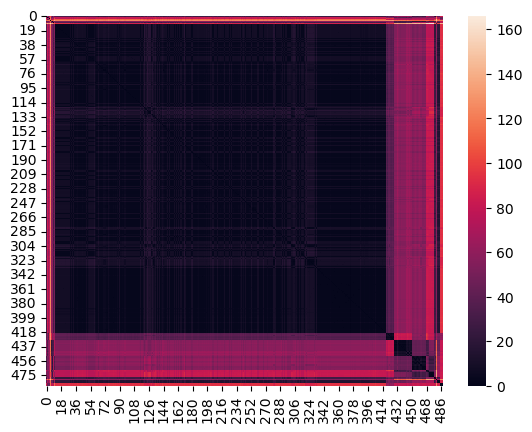

In [169]:
# Here is the same plot but with a larger clustering parameter value.
# This results in fewer clusters.

eps = 10
min_samples = 2

db = DBSCAN(eps=eps, min_samples=min_samples, metric='precomputed')
labels = db.fit_predict(distances)

sorted_indices = np.argsort(labels)
reordered_distances = distances[np.ix_(sorted_indices, sorted_indices)]
sns.heatmap(reordered_distances)

In [170]:
# Print size of each cluster
unique_labels, cluster_counts = np.unique(labels, return_counts=True)

for label, count in zip(unique_labels, cluster_counts):
    print(f"Cluster {label}: {count} items")

# The interpretation here is that 67 reads are in cluster -1 (meaning they are in a cluster by themselves),
# cluster 0 groups 262 reads together, etc.

Cluster -1: 11 items
Cluster 0: 408 items
Cluster 1: 10 items
Cluster 2: 21 items
Cluster 3: 18 items
Cluster 4: 3 items
Cluster 5: 7 items
Cluster 6: 2 items
Cluster 7: 2 items
Cluster 8: 3 items
Cluster 9: 4 items


## Cluster using ALL sequences, including duplicates

This takes a lot longer to run...

In [178]:
n_seqs = len(sequences)
print(f'There are {n_seqs} sequences.')

There are 5341 sequences.


In [179]:
# Compute Levenshtein distance between every pair of reads.
# for 5341 reads, this takes about a minute to run.
distances = np.zeros((n_seqs, n_seqs))
for i in trange(n_seqs):
    for j in range(n_seqs):
        distances[i, j] = Levenshtein.distance(sequences[i], sequences[j])

100%|██████████████████████████████████████| 5341/5341 [00:46<00:00, 114.65it/s]


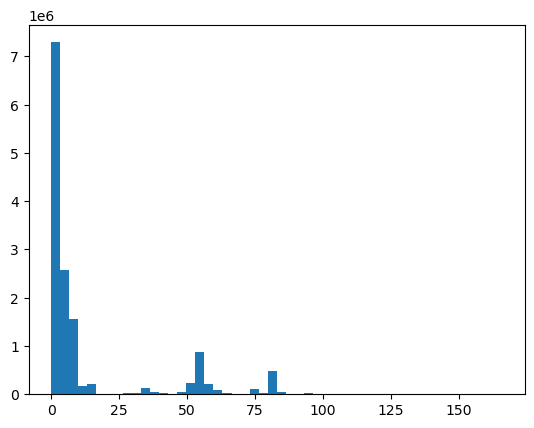

In [190]:
# Plot all the distances on a histogram.
plt.hist(distances[np.triu_indices(n_seqs)], bins=50);

# The left mode is a lot stronger here compared to when we removed duplicates - this makes sense to me.

<Axes: >

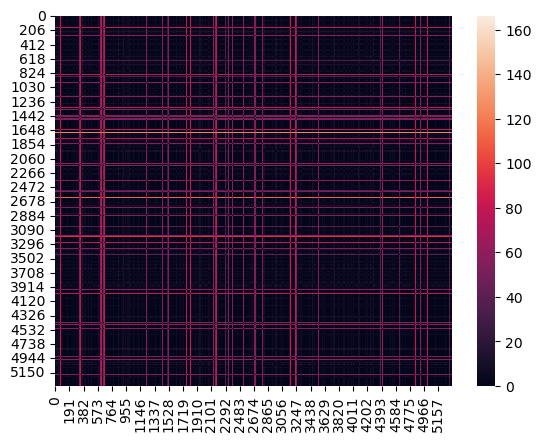

In [184]:
# The matrix plotted as a heatmap
sns.heatmap(distances)

In [191]:
# Cluster
eps = 1.0
min_samples = 2

db = DBSCAN(eps=eps, min_samples=min_samples, metric='precomputed')

# `labels` is an array containing the cluster identity of each read.
labels = db.fit_predict(distances)

In [192]:
# Print size of each cluster
unique_labels, cluster_counts = np.unique(labels, return_counts=True)

for label, count in zip(unique_labels, cluster_counts):
    print(f"Cluster {label}: {count} items")

# When we did not include duplicate sequences, we ended up with 18 clusters. Now, we have 33!

Cluster -1: 52 items
Cluster 0: 3651 items
Cluster 1: 6 items
Cluster 2: 857 items
Cluster 3: 195 items
Cluster 4: 113 items
Cluster 5: 2 items
Cluster 6: 194 items
Cluster 7: 33 items
Cluster 8: 53 items
Cluster 9: 41 items
Cluster 10: 3 items
Cluster 11: 13 items
Cluster 12: 16 items
Cluster 13: 8 items
Cluster 14: 21 items
Cluster 15: 3 items
Cluster 16: 11 items
Cluster 17: 9 items
Cluster 18: 6 items
Cluster 19: 3 items
Cluster 20: 3 items
Cluster 21: 9 items
Cluster 22: 5 items
Cluster 23: 8 items
Cluster 24: 2 items
Cluster 25: 3 items
Cluster 26: 4 items
Cluster 27: 3 items
Cluster 28: 2 items
Cluster 29: 2 items
Cluster 30: 4 items
Cluster 31: 2 items
Cluster 32: 2 items
Cluster 33: 2 items


<Axes: >

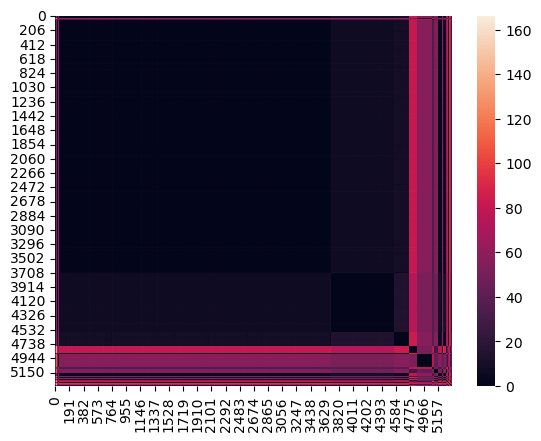

In [193]:
# Re-order the distance matrix based on the clusters and then plot.
sorted_indices = np.argsort(labels)
reordered_distances = distances[np.ix_(sorted_indices, sorted_indices)]

sns.heatmap(reordered_distances)

# Don't be fooled - that big square in the middle is actually 3 clusters. You may have to squint to see it :)

In [194]:
# Still TBD whether it is better to cluster with or without duplicate sequences, or if it doesn't really matter.